# Задача 2. Создание источника

В данном ноутбуке реализован класс `Source`, моделирующий изотропный источник сцинтилляционного света.
Количество испускаемых фотонов линейно зависит от энергии события `E` с коэффициентом `Y` (выход фотонов).

In [2]:
import numpy as np
import matplotlib.pyplot as plt

class Source:
    """
    Класс, описывающий изотропный источник света в сцинтилляторе.
    """
    def __init__(self, Y: float = 10000.0):
        """
        Инициализация источника.

        Параметры:
        Y -- выход фотонов на 1 МэВ энергии (фотонов/МэВ)
        """
        self.Y = Y

    def generate_photons(self, E: float) -> np.ndarray:
        """
        Генерирует начальные направления фотонов для события с энергией E.

        Параметры:
        E -- энергия события в МэВ

        Возвращает:
        Массив numpy формы (N, 3) с координатами (x, y, z) единичных векторов направлений.
        """
        # 1. Считаем количество фотонов (должно быть целым числом)
        N_photons = int(E * self.Y)

        # 2. Генерируем изотропные направления
        # Для равномерного распределения по сфере cos(theta) должен быть равномерным от -1 до 1
        phi = np.random.uniform(0, 2 * np.pi, N_photons)
        cos_theta = np.random.uniform(-1, 1, N_photons)
        sin_theta = np.sqrt(1 - cos_theta**2)

        # Переводим в декартовы координаты (единичные векторы)
        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        z = cos_theta

        # Объединяем в один массив формы (N, 3)
        directions = np.column_stack((x, y, z))

        return directions

Для энергии 2.0 МэВ сгенерировано фотонов: 20000 (Ожидалось: 20000)
Форма массива направлений: (20000, 3)
Средняя длина вектора (должна быть 1.0): 1.0000


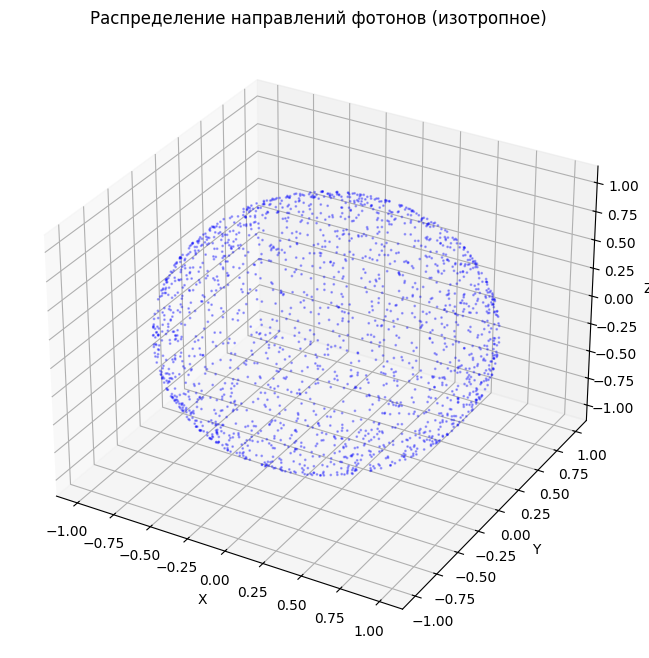

In [4]:
# Создаем источник
src = Source(Y=10000)

# Генерируем фотоны для события с энергией 2 МэВ
E_event = 2.0 # МэВ
directions = src.generate_photons(E_event)

print(f"Для энергии {E_event} МэВ сгенерировано фотонов: {len(directions)} (Ожидалось: {int(E_event * 10000)})")
print(f"Форма массива направлений: {directions.shape}")

# Проверим, что векторы единичные
norms = np.linalg.norm(directions, axis=1)
print(f"Средняя длина вектора (должна быть 1.0): {np.mean(norms):.4f}")

# Визуализация изотропности (3D график)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Берем подвыборку (например, первые 2000 фотонов), чтобы график не тормозил
sample = directions[:2000]
ax.scatter(sample[:, 0], sample[:, 1], sample[:, 2], alpha=0.3, s=1, color='blue')

ax.set_title('Распределение направлений фотонов (изотропное)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()